# Mutual Fund Investment Plan with Python (Nifty 50)


In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.4f}".format

## 1. Data collection & preparation

In [ ]:
prices = pd.read_csv("nifty50_closing_prices.csv", parse_dates=["Date"]).set_index("Date").sort_index()
prices = prices[~prices.index.duplicated(keep="last")]
prices = prices.apply(pd.to_numeric, errors="coerce")

# Cleaning: forward-fill small gaps, drop stocks that still have missing values
prices = prices.dropna(axis=1, how="all").ffill()
dropped = prices.columns[prices.isna().any()].tolist()
prices = prices.drop(columns=dropped)

# Safety check: raw prices are always > 0. Standardized data (mean 0) will fail here.
assert (prices > 0).all().all(), "Non-positive prices found - data looks standardized/scaled. Use the raw CSV."

rets = prices.pct_change().dropna()
n_years = (prices.index[-1] - prices.index[0]).days / 365.25

print(f"Stocks: {prices.shape[1]} | Trading days: {len(prices)} | Period: {prices.index[0].date()} -> {prices.index[-1].date()} ({n_years:.2f} years)")
print("Dropped (missing data):", dropped or "none")
if n_years < 3:
    print("WARNING: less than 3 years of history - annualized figures are noisy. Use 3-5+ years if possible.")
prices.head()

Stocks: 49 | Trading days: 348 | Period: 2024-01-01 -> 2025-05-30 (1.41 years)
Dropped (missing data): none


,ADANIENT.NS,ADANIPORTS.NS,APOLLOHOSP.NS,ASIANPAINT.NS,AXISBANK.NS,BAJAJ-AUTO.NS,BAJAJFINSV.NS,BAJFINANCE.NS,BHARTIARTL.NS,BPCL.NS,BRITANNIA.NS,CIPLA.NS,COALINDIA.NS,DIVISLAB.NS,DRREDDY.NS,EICHERMOT.NS,GRASIM.NS,HCLTECH.NS,HDFCBANK.NS,HDFCLIFE.NS,HEROMOTOCO.NS,HINDALCO.NS,HINDUNILVR.NS,ICICIBANK.NS,INDUSINDBK.NS,INFY.NS,ITC.NS,JSWSTEEL.NS,KOTAKBANK.NS,LT.NS,M&M.NS,MARUTI.NS,NESTLEIND.NS,NTPC.NS,ONGC.NS,POWERGRID.NS,RELIANCE.NS,SBILIFE.NS,SBIN.NS,SHREECEM.NS,SUNPHARMA.NS,TATAMOTORS.NS,TATASTEEL.NS,TCS.NS,TECHM.NS,TITAN.NS,ULTRACEMCO.NS,UPL.NS,WIPRO.NS
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2024-01-01,"2,914.5339","1,038.3218","5,727.9497","3,327.1040","1,096.8534","6,647.0771","1,675.3430",659.3982,"1,007.4357",214.7662,"5,251.4463","1,240.4819",355.1929,"3,892.0122","1,157.4757","3,994.0957","2,110.7637","1,411.3687","1,675.2240",646.5014,"3,967.0784",606.9208,"2,618.7078",990.8698,"1,581.2948","1,491.4094",438.1210,870.7787,"1,907.0598","3,465.6313","1,690.9191","10,187.0791","2,700.4548",300.1486,192.1943,226.4627,"1,295.1250","1,426.8167",618.3558,"28,304.2637","1,241.6625",781.4490,133.9639,"3,665.4329","1,262.2179","3,665.1570","10,402.3115",592.7000,233.4288
2024-01-02,"2,929.7200","1,068.5940","5,724.2632","3,322.4504","1,092.4070","6,611.3179","1,685.1368",671.2328,"1,016.0378",216.7616,"5,220.8945","1,270.7751",365.2868,"4,005.4163","1,178.3818","3,849.8438","2,085.1145","1,397.8613","1,676.2106",643.3123,"3,937.8447",613.4832,"2,578.3137",973.8661,"1,558.3000","1,475.1144",440.2740,863.4363,"1,863.0082","3,379.7637","1,644.1613","10,102.3301","2,685.7302",296.5149,193.7854,226.0825,"1,305.8500","1,432.3461",616.5239,"27,933.2773","1,277.0822",775.3208,133.7244,"3,638.5991","1,243.6808","3,686.1882","10,144.5400",594.4500,229.5396
2024-01-03,"3,000.2554","1,084.2998","5,746.1289","3,305.0610","1,097.7528","6,930.1763","1,676.5923",667.1449,"1,029.4630",219.0420,"5,186.2944","1,289.2188",357.7513,"4,006.0127","1,179.3959","3,844.9976","2,056.0920","1,367.6127","1,650.3635",635.0404,"3,843.1121",589.6697,"2,571.1624",975.6508,"1,583.5696","1,432.4298",446.7328,831.1393,"1,863.8572","3,381.9756","1,643.2183","9,983.3545","2,627.7256",296.7087,194.9085,225.3221,"1,291.6500","1,417.4513",620.3806,"28,065.7402","1,279.4468",772.4050,129.6533,"3,550.6445","1,210.6938","3,681.0054","10,051.9395",586.8500,223.0330
2024-01-04,"2,995.5598","1,112.9866","5,740.0527","3,311.2820","1,122.5337","6,866.3452","1,700.8768",696.1216,"1,042.0927",215.0512,"5,292.4131","1,285.7482",357.9373,"4,017.4922","1,161.5614","3,818.6890","2,054.1074","1,350.6810","1,668.0718",645.7540,"3,801.7898",587.1342,"2,557.3523",978.7244,"1,630.4491","1,454.2527",445.9371,830.5936,"1,861.5597","3,400.0139","1,629.7667","9,921.5869","2,675.1987",307.2708,200.8985,229.5044,"1,298.3250","1,426.3184",619.7056,"28,201.1387","1,293.5852",786.5394,128.5996,"3,526.6482","1,213.9049","3,707.5684","9,955.7598",587.6500,221.3208
2024-01-05,"3,003.8521","1,143.7543","5,732.1333","3,287.3777","1,136.0731","6,922.2407","1,708.4221",696.6274,"1,040.7998",215.2650,"5,204.6064","1,276.0802",357.4722,"3,990.2593","1,160.2592","3,834.5632","2,063.3352","1,362.9042","1,659.5382",644.5580,"3,843.5457",583.6542,"2,584.4788",985.2184,"1,625.1578","1,473.3358",443.6438,822.9534,"1,845.5771","3,462.1414","1,630.0646","9,923.2715","2,630.5667",305.1874,202.5831,229.3143,"1,303.8500","1,448.7853",618.9343,"26,873.9160","1,281.0232",781.7950,128.0248,"3,595.0308","1,214.6835","3,700.4417","9,957.0020",581.2500,223.3755


## 2. Key metrics per stock
Total return, annualized return (CAGR), volatility, **Sharpe**, **Sortino**, max drawdown.

In [ ]:
TRADING_DAYS   = 252
RISK_FREE_RATE = 0.07      # annual, approx. Indian 10Y G-Sec yield

total_return = prices.iloc[-1] / prices.iloc[0] - 1
cagr         = (1 + total_return) ** (1 / n_years) - 1
ann_vol      = rets.std() * np.sqrt(TRADING_DAYS)
ann_mean     = rets.mean() * TRADING_DAYS

downside_dev = np.sqrt((np.minimum(rets - RISK_FREE_RATE / TRADING_DAYS, 0) ** 2).mean()) * np.sqrt(TRADING_DAYS)
sharpe       = (ann_mean - RISK_FREE_RATE) / ann_vol
sortino      = (ann_mean - RISK_FREE_RATE) / downside_dev
max_dd       = (prices / prices.cummax() - 1).min()

metrics = pd.DataFrame({
    "TotalReturn": total_return, "CAGR": cagr, "Volatility": ann_vol,
    "Sharpe": sharpe, "Sortino": sortino, "MaxDrawdown": max_dd,
})
metrics.round(4).sort_values("Sharpe", ascending=False).head(15)

,TotalReturn,CAGR,Volatility,Sharpe,Sortino,MaxDrawdown
BHARTIARTL.NS,0.8425,0.5425,0.2338,1.7170,2.7076,-0.1389
DIVISLAB.NS,0.6989,0.4562,0.2750,1.2821,2.0787,-0.1668
M&M.NS,0.7605,0.4935,0.3198,1.2255,1.8672,-0.2242
ICICIBANK.NS,0.4591,0.3073,0.2050,1.1000,1.6204,-0.1114
SUNPHARMA.NS,0.3511,0.2379,0.2115,0.8081,1.1893,-0.1913
BPCL.NS,0.4825,0.3222,0.3387,0.8076,1.1768,-0.3459
BAJFINANCE.NS,0.3923,0.2645,0.2718,0.7627,1.1216,-0.1842
EICHERMOT.NS,0.3353,0.2276,0.2598,0.6681,1.0368,-0.1425
ADANIPORTS.NS,0.3732,0.2523,0.3831,0.6172,0.8296,-0.3378
SBIN.NS,0.3136,0.2135,0.2756,0.6045,0.8529,-0.2394


In [ ]:
rank_specs = {
    "Highest total return (ROI)": ("TotalReturn", False),
    "Lowest volatility":          ("Volatility",  True),
    "Highest Sharpe ratio":       ("Sharpe",      False),
    "Highest Sortino ratio":      ("Sortino",     False),
}
for title, (col, asc) in rank_specs.items():
    print(f"\nTop 10 - {title}")
    print(metrics[col].sort_values(ascending=asc).head(10).round(4).to_string())


Top 10 - Highest total return (ROI)
BHARTIARTL.NS   0.8425
M&M.NS          0.7605
DIVISLAB.NS     0.6989
BPCL.NS         0.4825
ICICIBANK.NS    0.4591
BAJFINANCE.NS   0.3923
ADANIPORTS.NS   0.3732
SUNPHARMA.NS    0.3511
EICHERMOT.NS    0.3353
SBIN.NS         0.3136

Top 10 - Lowest volatility
NESTLEIND.NS    0.1927
ITC.NS          0.1986
ICICIBANK.NS    0.2050
HINDUNILVR.NS   0.2059
BRITANNIA.NS    0.2102
ASIANPAINT.NS   0.2107
SUNPHARMA.NS    0.2115
DRREDDY.NS      0.2116
HDFCBANK.NS     0.2166
TCS.NS          0.2174

Top 10 - Highest Sharpe ratio
BHARTIARTL.NS   1.7170
DIVISLAB.NS     1.2821
M&M.NS          1.2255
ICICIBANK.NS    1.1000
SUNPHARMA.NS    0.8081
BPCL.NS         0.8076
BAJFINANCE.NS   0.7627
EICHERMOT.NS    0.6681
ADANIPORTS.NS   0.6172
SBIN.NS         0.6045

Top 10 - Highest Sortino ratio
BHARTIARTL.NS   2.7076
DIVISLAB.NS     2.0787
M&M.NS          1.8672
ICICIBANK.NS    1.6204
SUNPHARMA.NS    1.1893
BPCL.NS         1.1768
BAJFINANCE.NS   1.1216
EICHERMOT.NS    1.036

## 3. Stock selection (positive return, high return + low risk)
Only stocks with positive CAGR are kept; return and volatility are min-max normalized; score = `w*norm_return + (1-w)*(1-norm_volatility)`.

In [ ]:
TOP_N = 10            # number of stocks in the plan
WEIGHT_RETURN = 0.5   # score = 0.5*return + 0.5*(1 - volatility), both normalized

eligible = metrics[metrics["CAGR"] > 0].copy()
minmax = lambda s: (s - s.min()) / (s.max() - s.min())
eligible["NormReturn"] = minmax(eligible["CAGR"])
eligible["NormVol"]    = minmax(eligible["Volatility"])
eligible["Score"]      = WEIGHT_RETURN * eligible["NormReturn"] + (1 - WEIGHT_RETURN) * (1 - eligible["NormVol"])

selected = eligible["Score"].nlargest(TOP_N).index.tolist()
print(f"{len(eligible)} of {len(metrics)} stocks have positive CAGR\n")
eligible.loc[selected, ["CAGR", "Volatility", "Sharpe", "Sortino", "Score"]].round(4)

40 of 49 stocks have positive CAGR


,CAGR,Volatility,Sharpe,Sortino,Score
BHARTIARTL.NS,0.5425,0.2338,1.7170,2.7076,0.9193
ICICIBANK.NS,0.3073,0.2050,1.1000,1.6204,0.7701
DIVISLAB.NS,0.4562,0.2750,1.2821,2.0787,0.7191
SUNPHARMA.NS,0.2379,0.2115,0.8081,1.1893,0.6841
M&M.NS,0.4935,0.3198,1.2255,1.8672,0.6297
APOLLOHOSP.NS,0.1389,0.2239,0.3940,0.5542,0.5525
MARUTI.NS,0.1443,0.2276,0.4117,0.6458,0.5476
HDFCBANK.NS,0.1117,0.2166,0.2863,0.3862,0.5464
BAJFINANCE.NS,0.2645,0.2718,0.7627,1.1216,0.5410
EICHERMOT.NS,0.2276,0.2598,0.6681,1.0368,0.5386


## 4. Portfolio construction (equal-weight, conservative, balanced, aggressive)

In [ ]:
RISK_TOLERANCE = "balanced"   # "conservative" | "balanced" | "aggressive"
MAX_WEIGHT = 0.30             # max weight per stock

mu_ann = rets[selected].mean() * TRADING_DAYS
cov_ann = rets[selected].cov() * TRADING_DAYS

def port_stats(w, mu=mu_ann, cov=cov_ann):
    w = np.asarray(w, dtype=float)
    r = float(w @ mu.values)
    v = float(np.sqrt(w @ cov.values @ w))
    return r, v, (r - RISK_FREE_RATE) / v

def optimize(objective):
    n = len(selected)
    res = minimize(objective, np.full(n, 1 / n), method="SLSQP",
                   bounds=[(0, MAX_WEIGHT)] * n,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    return pd.Series(res.x, index=selected).clip(lower=0).pipe(lambda s: s / s.sum())

w_equal  = pd.Series(1 / TOP_N, index=selected)
w_minvol = optimize(lambda w: port_stats(w)[1])                 # conservative
w_maxsh  = optimize(lambda w: -port_stats(w)[2])                # aggressive (max Sharpe)

profiles = {"conservative": w_minvol, "balanced": w_equal, "aggressive": w_maxsh}
weights = profiles[RISK_TOLERANCE]

table = pd.DataFrame({k: v for k, v in profiles.items()})
table.loc["Exp. return"], table.loc["Volatility"], table.loc["Sharpe"] = zip(*[port_stats(profiles[k]) for k in profiles])
print(f"Selected profile: {RISK_TOLERANCE}")
table.round(4)

Selected profile: balanced


,conservative,balanced,aggressive
BHARTIARTL.NS,0.0879,0.1000,0.3000
ICICIBANK.NS,0.1502,0.1000,0.2534
DIVISLAB.NS,0.0754,0.1000,0.3000
SUNPHARMA.NS,0.1991,0.1000,0.0122
M&M.NS,0.0000,0.1000,0.1339
APOLLOHOSP.NS,0.1639,0.1000,0.0000
MARUTI.NS,0.1253,0.1000,0.0000
HDFCBANK.NS,0.1804,0.1000,0.0000
BAJFINANCE.NS,0.0177,0.1000,0.0005
EICHERMOT.NS,0.0000,0.1000,0.0000


Average pairwise correlation: 0.28  -> well diversified


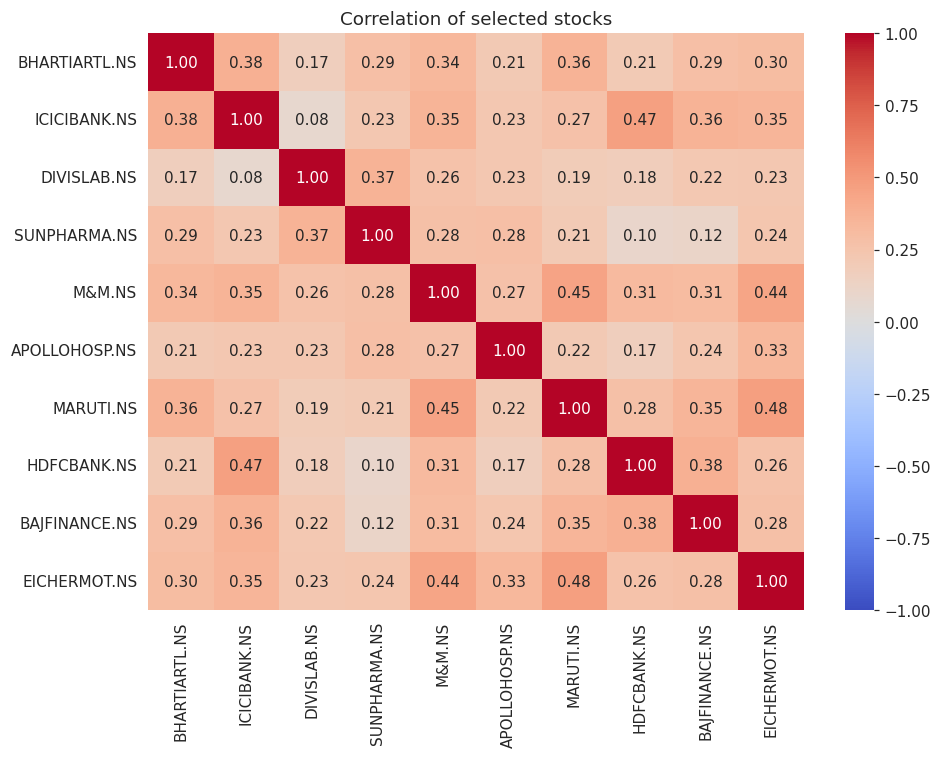

In [ ]:
# Diversification check: average pairwise correlation among selected stocks
corr = rets[selected].corr()
avg_corr = corr.values[np.triu_indices_from(corr.values, k=1)].mean()
print(f"Average pairwise correlation: {avg_corr:.2f}  ->", "well diversified" if avg_corr < 0.4 else "moderately correlated - consider adding other sectors" )

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation of selected stocks")
plt.tight_layout(); plt.show()

## 5. Performance vs benchmark

,Plan portfolio,Equal-weight Nifty 50 (benchmark)
CAGR,0.3094,0.1238
Volatility,0.1457,0.1477
Sharpe,1.4876,0.4096
Sortino,2.2300,0.5729
MaxDrawdown,-0.0816,-0.1674


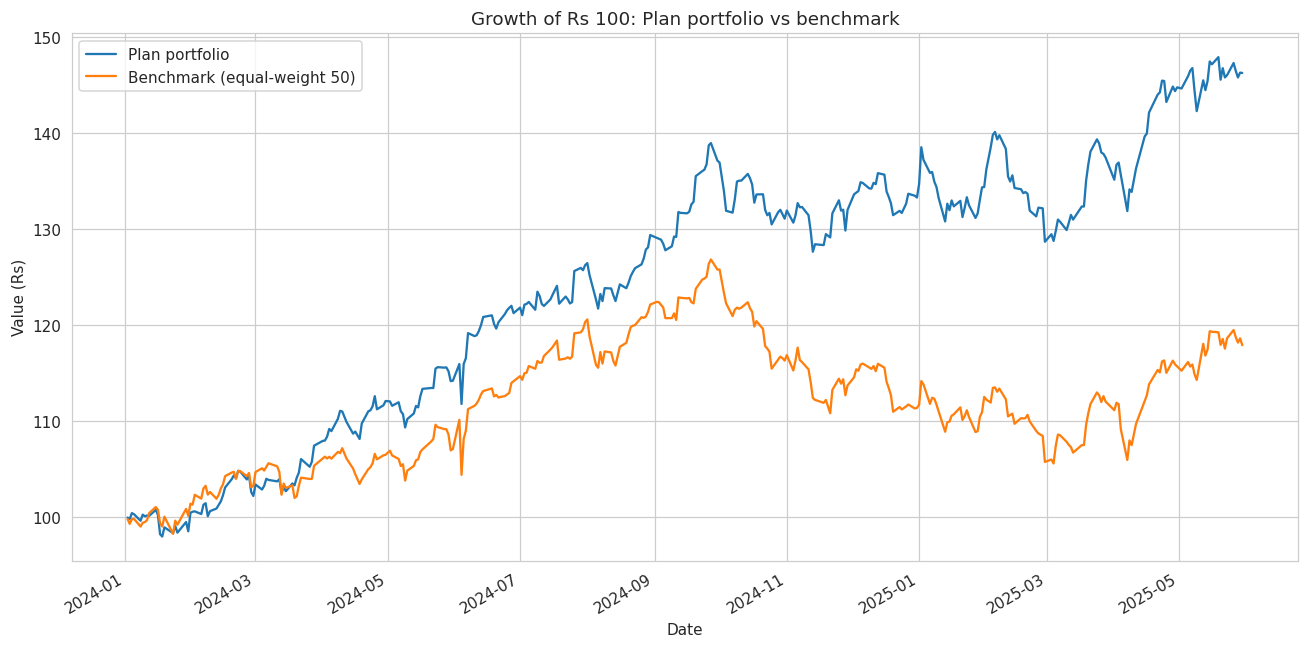

In [ ]:
port_rets  = (rets[selected] * weights).sum(axis=1)      # daily-rebalanced weights
bench_rets = rets.mean(axis=1)                           # equal-weight of all stocks (proxy for Nifty 50)

def summarize(r, name):
    cagr_ = (1 + r).prod() ** (1 / n_years) - 1
    vol_  = r.std() * np.sqrt(TRADING_DAYS)
    dd    = r.sub(RISK_FREE_RATE / TRADING_DAYS)
    sharpe_  = (r.mean() * TRADING_DAYS - RISK_FREE_RATE) / vol_
    sortino_ = (r.mean() * TRADING_DAYS - RISK_FREE_RATE) / (np.sqrt((np.minimum(dd, 0) ** 2).mean()) * np.sqrt(TRADING_DAYS))
    cum = (1 + r).cumprod()
    return pd.Series({"CAGR": cagr_, "Volatility": vol_, "Sharpe": sharpe_, "Sortino": sortino_,
                      "MaxDrawdown": (cum / cum.cummax() - 1).min()}, name=name)

summary = pd.concat([summarize(port_rets, "Plan portfolio"), summarize(bench_rets, "Equal-weight Nifty 50 (benchmark)")], axis=1)
display(summary.round(4)) if "display" in globals() else print(summary.round(4))

growth = pd.DataFrame({"Plan portfolio": (1 + port_rets).cumprod() * 100,
                       "Benchmark (equal-weight 50)": (1 + bench_rets).cumprod() * 100})
growth.plot(figsize=(12, 6), title="Growth of Rs 100: Plan portfolio vs benchmark")
plt.ylabel("Value (Rs)"); plt.tight_layout(); plt.show()

## 6. Visualizations: risk-return scatter, composition pie, monthly heatmap

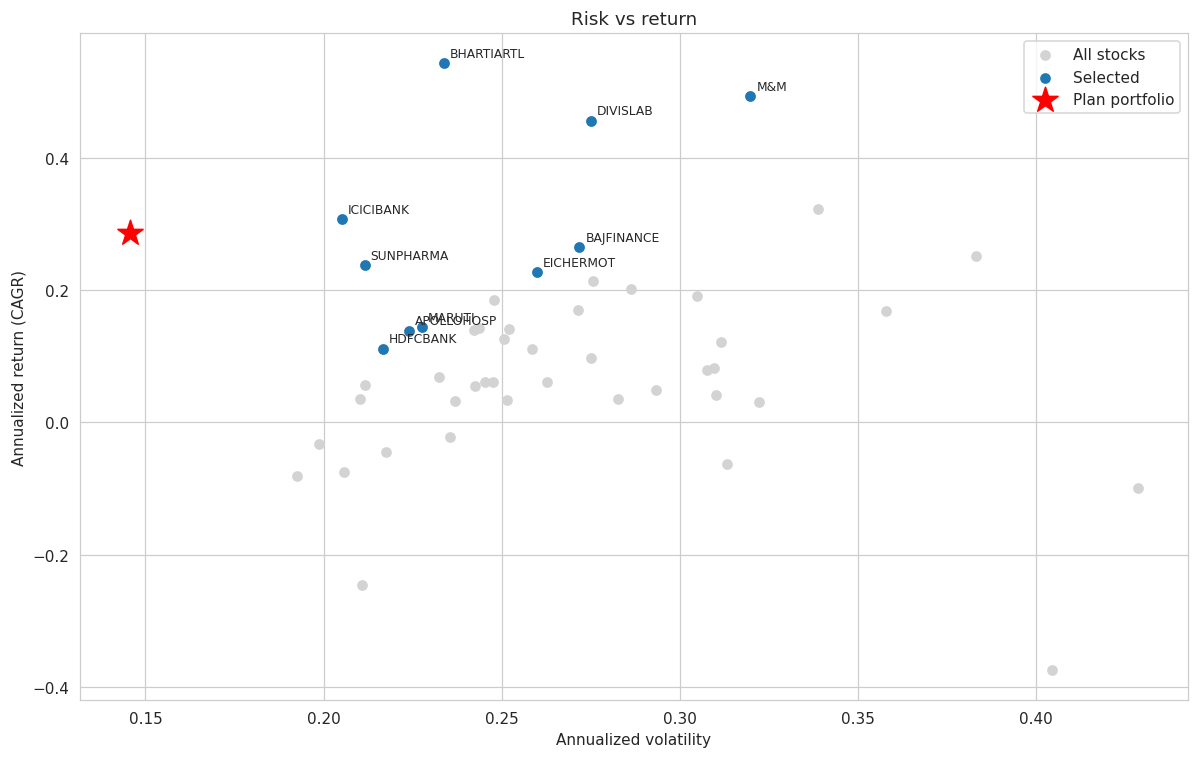

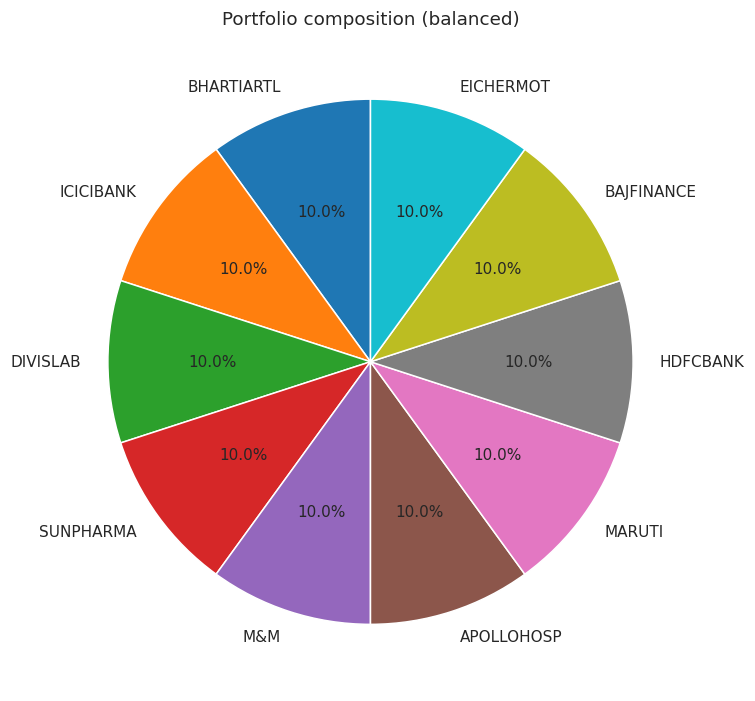

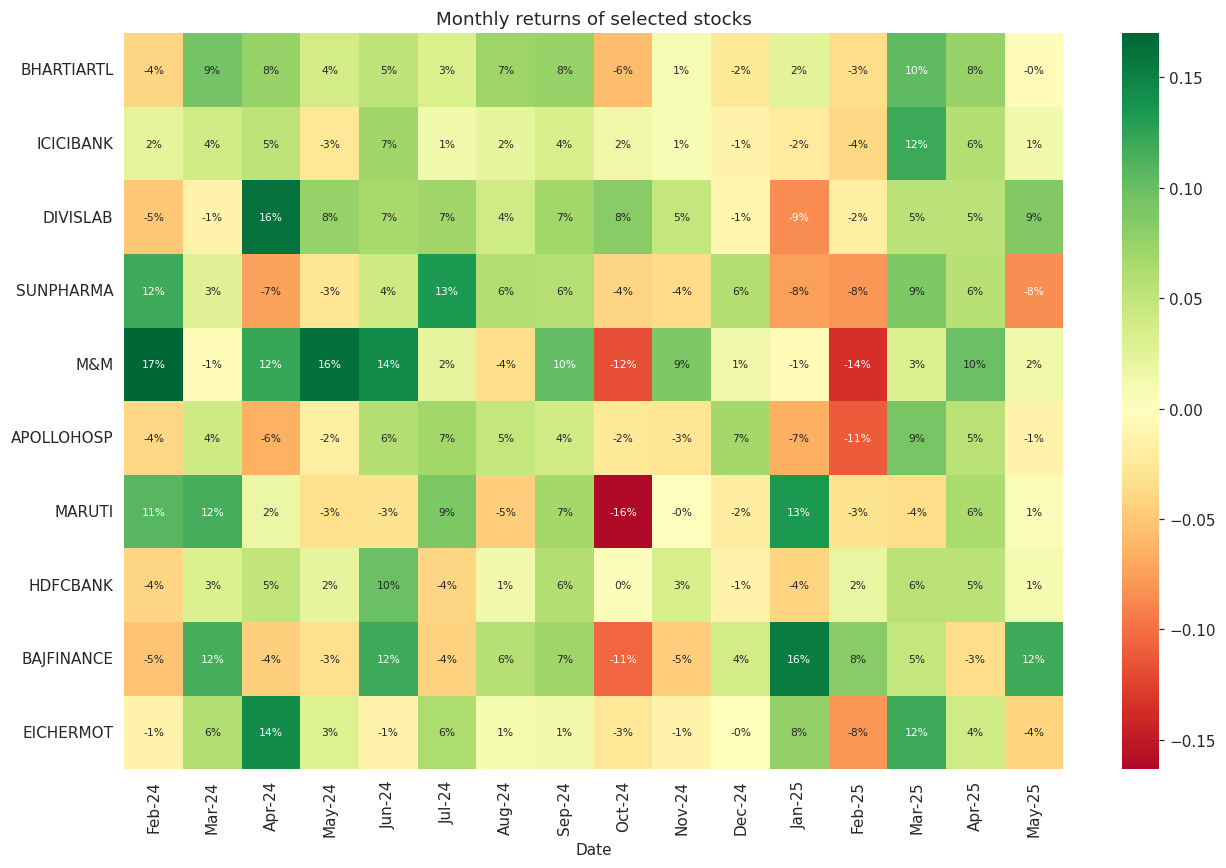

In [ ]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(metrics["Volatility"], metrics["CAGR"], c="lightgray", label="All stocks")
ax.scatter(metrics.loc[selected, "Volatility"], metrics.loc[selected, "CAGR"], c="tab:blue", label="Selected")
for s in selected:
    ax.annotate(s.replace(".NS", ""), (metrics.loc[s, "Volatility"], metrics.loc[s, "CAGR"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
pr, pv, _ = port_stats(weights)
ax.scatter(pv, pr, marker="*", s=300, c="red", label="Plan portfolio")
ax.set_xlabel("Annualized volatility"); ax.set_ylabel("Annualized return (CAGR)")
ax.set_title("Risk vs return"); ax.legend(); plt.tight_layout(); plt.show()

w_plot = weights[weights > 0.005]
plt.figure(figsize=(7, 7))
plt.pie(w_plot, labels=[s.replace(".NS", "") for s in w_plot.index], autopct="%1.1f%%", startangle=90)
plt.title(f"Portfolio composition ({RISK_TOLERANCE})"); plt.tight_layout(); plt.show()

try:
    monthly = prices[selected].resample("ME").last().pct_change().dropna()
except ValueError:
    monthly = prices[selected].resample("M").last().pct_change().dropna()
monthly.index = monthly.index.strftime("%b-%y")
plt.figure(figsize=(12, 8))
sns.heatmap(monthly.T.rename(index=lambda s: s.replace(".NS", "")), cmap="RdYlGn", center=0, annot=True, fmt=".0%", annot_kws={"size": 7})
plt.title("Monthly returns of selected stocks"); plt.tight_layout(); plt.show()

## 7. Mean-variance optimization: efficient frontier

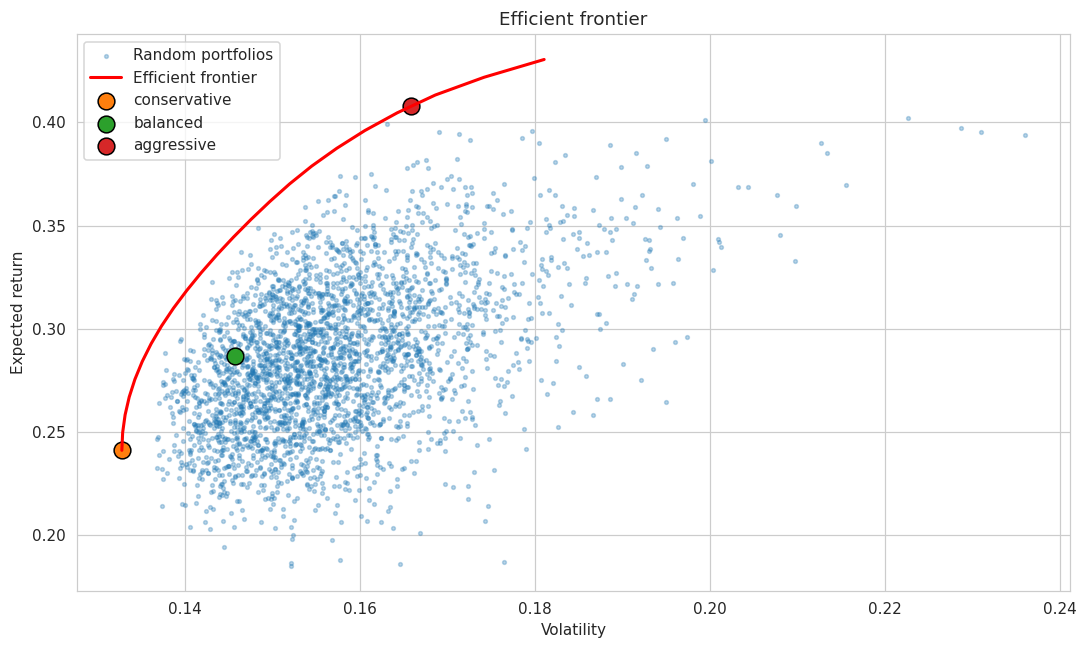

In [ ]:
SEED = 42
targets = np.linspace(port_stats(w_minvol)[0], mu_ann.max() * 0.95, 25)
frontier = []
for t in targets:
    res = minimize(lambda w: port_stats(w)[1], np.full(len(selected), 1 / len(selected)), method="SLSQP",
                   bounds=[(0, MAX_WEIGHT)] * len(selected),
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                {"type": "eq", "fun": lambda w, t=t: w @ mu_ann.values - t}])
    if res.success:
        frontier.append((res.fun, t))
frontier = np.array(frontier)

# random portfolios for context
rng = np.random.default_rng(SEED)
rand = rng.dirichlet(np.ones(len(selected)), 3000)
rs = np.array([port_stats(w)[:2][::-1] for w in rand])

plt.figure(figsize=(10, 6))
plt.scatter(rs[:, 0], rs[:, 1], s=6, alpha=0.3, label="Random portfolios")
if len(frontier): plt.plot(frontier[:, 0], frontier[:, 1], "r-", lw=2, label="Efficient frontier")
for name, w in profiles.items():
    r_, v_, _ = port_stats(w); plt.scatter(v_, r_, s=120, label=name, edgecolor="k")
plt.xlabel("Volatility"); plt.ylabel("Expected return"); plt.title("Efficient frontier"); plt.legend(); plt.tight_layout(); plt.show()

## 8. Sensitivity analysis

In [ ]:
# (a) How shifting allocation between minimum-risk and max-Sharpe mixes changes risk/return
rows = []
for a in np.linspace(0, 1, 6):
    w = (1 - a) * w_minvol + a * w_maxsh
    r_, v_, s_ = port_stats(w)
    rows.append({"Share in max-Sharpe mix": a, "Return": r_, "Volatility": v_, "Sharpe": s_})
print("Allocation sensitivity"); print(pd.DataFrame(rows).round(4).to_string(index=False))

# (b) SIP sensitivity to expected return and step-up is shown in section 9

Allocation sensitivity
 Share in max-Sharpe mix  Return  Volatility  Sharpe
                  0.0000  0.2409      0.1328  1.2865
                  0.2000  0.2743      0.1351  1.5120
                  0.4000  0.3077      0.1398  1.7002
                  0.6000  0.3412      0.1467  1.8482
                  0.8000  0.3746      0.1555  1.9589
                  1.0000  0.4080      0.1659  2.0380


## 9. SIP projections (monthly investment with annual step-up)
Payments are made at the end of each month; the monthly amount rises by `ANNUAL_STEP_UP` every year.
**Expected return is an assumption, not the 1-2 year historical return** (extrapolating a short bull run for 10 years is unrealistic), so three scenarios are shown.

Lump sum Rs 100,000 + SIP Rs 5,000/month, +10% per year

           Invested Conservative (8.0%)  Base (12.0%) History-based (capped 20%) (20.0%)
Years                                                                                   
1        Rs 160,000          Rs 170,169    Rs 175,232                         Rs 185,319
3        Rs 298,600          Rs 347,568    Rs 374,225                         Rs 432,117
5        Rs 466,306          Rs 585,793    Rs 656,269                         Rs 822,209
10     Rs 1,056,245        Rs 1,567,510  Rs 1,929,671                       Rs 2,969,349


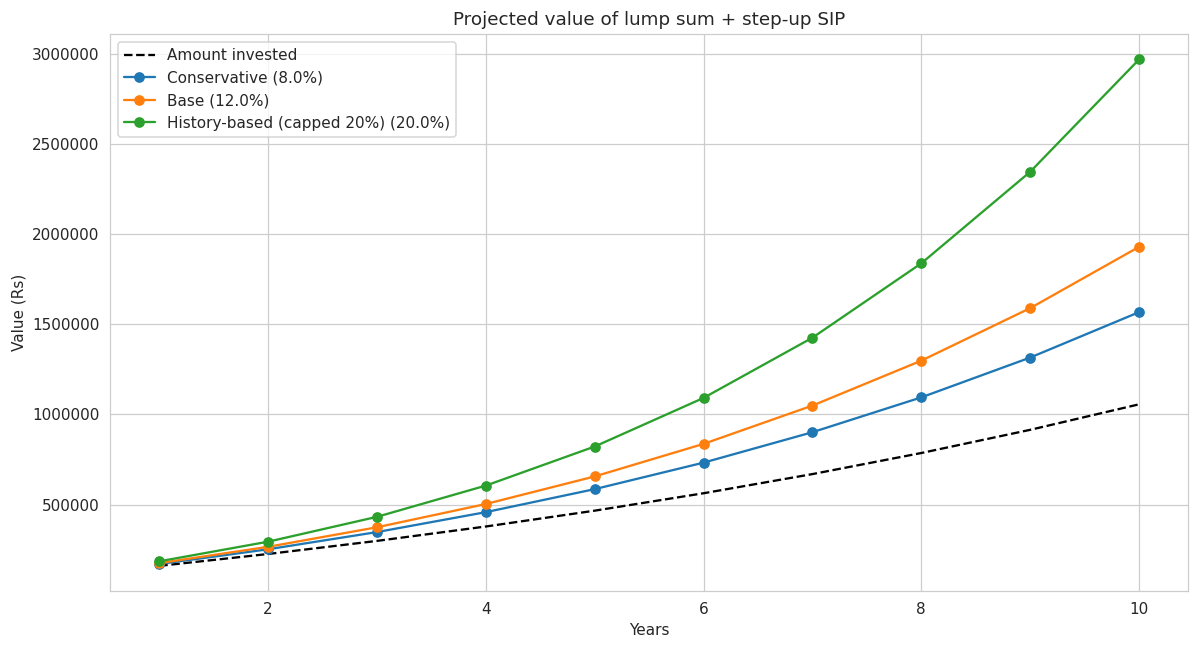

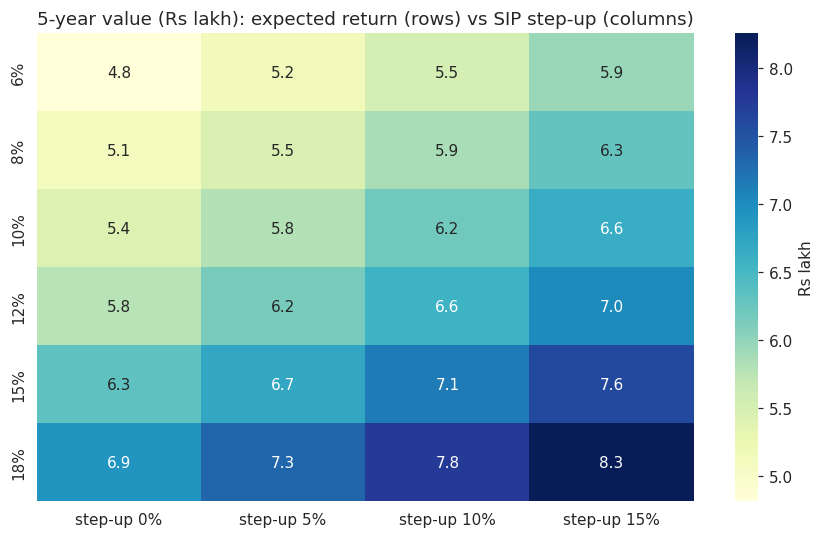

In [ ]:
LUMP_SUM        = 100_000        # initial investment (Rs)
MONTHLY_SIP     = 5_000          # starting monthly SIP (Rs)
ANNUAL_STEP_UP  = 0.10           # SIP rises 10% every year
HORIZONS        = [1, 3, 5, 10]  # years
SCENARIOS       = {"Conservative": 0.08, "Base": 0.12}   # expected annual returns
HIST_RETURN_CAP = 0.20           # cap for the history-based scenario

def inr(x): return f"Rs {x:,.0f}"

def sip_value(monthly, annual_rate, years, step_up, lump=0.0):
    r = (1 + annual_rate) ** (1 / 12) - 1
    months = int(years * 12)
    fv = lump * (1 + r) ** months
    invested = lump
    for m in range(months):
        c = monthly * (1 + step_up) ** (m // 12)
        fv += c * (1 + r) ** (months - 1 - m)
        invested += c
    return fv, invested

port_hist_cagr = float(summary.loc["CAGR", "Plan portfolio"])
scenarios = dict(SCENARIOS)
scenarios[f"History-based (capped {HIST_RETURN_CAP:.0%})"] = min(port_hist_cagr, HIST_RETURN_CAP)

rows = []
for y in HORIZONS:
    row = {"Years": y, "Invested": sip_value(MONTHLY_SIP, 0, y, ANNUAL_STEP_UP, LUMP_SUM)[1]}
    for name, rate in scenarios.items():
        row[f"{name} ({rate:.1%})"] = sip_value(MONTHLY_SIP, rate, y, ANNUAL_STEP_UP, LUMP_SUM)[0]
    rows.append(row)
proj = pd.DataFrame(rows).set_index("Years")
print(f"Lump sum {inr(LUMP_SUM)} + SIP {inr(MONTHLY_SIP)}/month, +{ANNUAL_STEP_UP:.0%} per year\n")
print(proj.map(inr).to_string() if hasattr(proj, "map") else proj.applymap(inr).to_string())

yrs = np.arange(1, max(HORIZONS) + 1)
plt.figure(figsize=(11, 6))
plt.plot(yrs, [sip_value(MONTHLY_SIP, 0, y, ANNUAL_STEP_UP, LUMP_SUM)[1] for y in yrs], "k--", label="Amount invested")
for name, rate in scenarios.items():
    plt.plot(yrs, [sip_value(MONTHLY_SIP, rate, y, ANNUAL_STEP_UP, LUMP_SUM)[0] for y in yrs], marker="o", label=f"{name} ({rate:.1%})")
plt.xlabel("Years"); plt.ylabel("Value (Rs)"); plt.title("Projected value of lump sum + step-up SIP")
plt.ticklabel_format(style="plain", axis="y"); plt.legend(); plt.tight_layout(); plt.show()

# Sensitivity (b): 5-year value vs expected return and step-up
sens = pd.DataFrame({f"step-up {s:.0%}": {f"{r:.0%}": sip_value(MONTHLY_SIP, r, 5, s, LUMP_SUM)[0]
                                           for r in [0.06, 0.08, 0.10, 0.12, 0.15, 0.18]} for s in [0, 0.05, 0.10, 0.15]})
plt.figure(figsize=(8, 5))
sns.heatmap(sens / 1e5, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Rs lakh"})
plt.title("5-year value (Rs lakh): expected return (rows) vs SIP step-up (columns)"); plt.tight_layout(); plt.show()

## 10. Monte Carlo simulation of future outcomes

After 10 years (invested Rs 1,056,245):
  5th percentile : Rs 1,177,183
  Median         : Rs 1,832,650
  95th percentile: Rs 3,106,565
  Probability of ending below amount invested: 1.9%


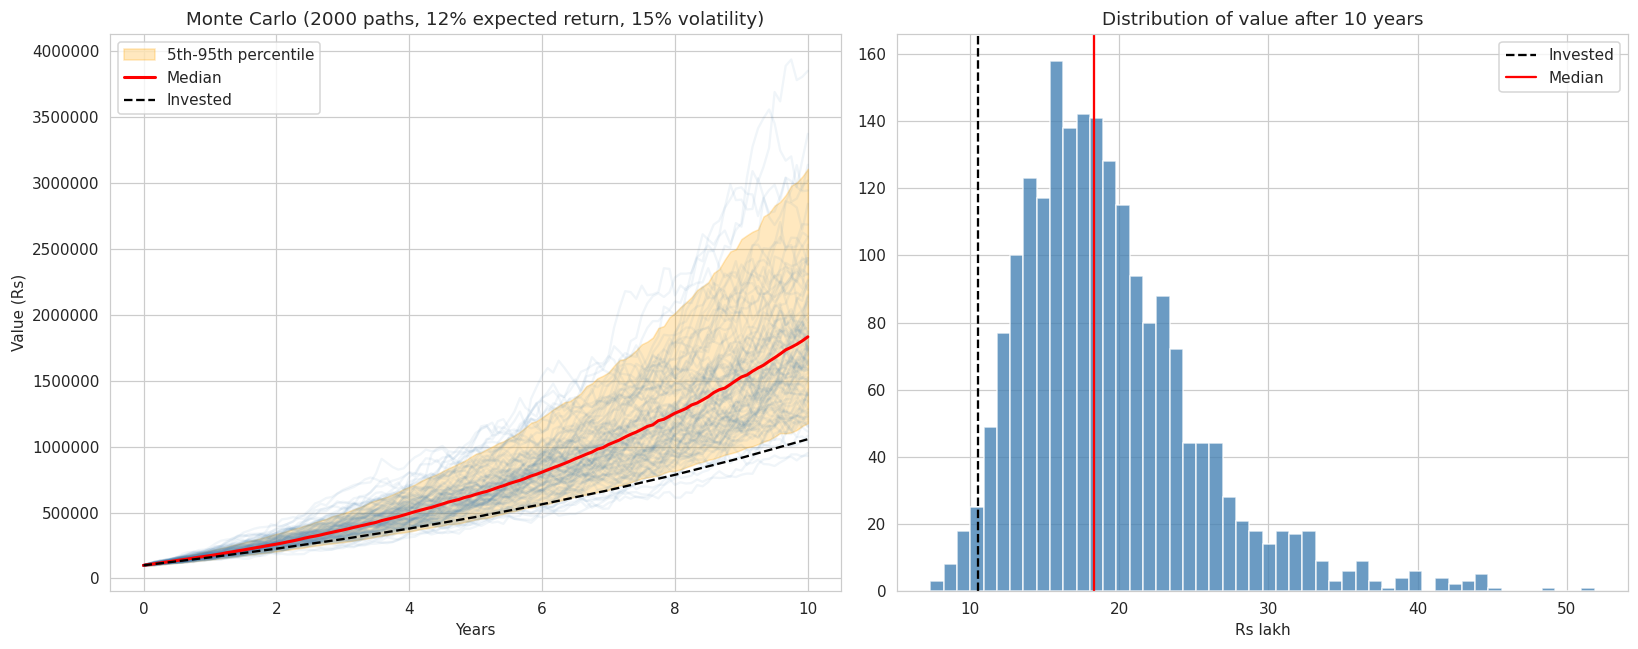

In [ ]:
N_SIMS, MC_YEARS = 2000, 10
rng = np.random.default_rng(SEED)
mu_mc    = SCENARIOS["Base"]                         # expected annual return assumption
sigma_ann = port_stats(weights)[1]                   # portfolio volatility from history
months = MC_YEARS * 12
sig_m = sigma_ann / np.sqrt(12)
drift_m = np.log(1 + mu_mc) / 12 - 0.5 * sig_m ** 2
growth_m = np.exp(rng.normal(drift_m, sig_m, size=(N_SIMS, months)))   # lognormal monthly growth factors

paths = np.empty((N_SIMS, months + 1)); paths[:, 0] = LUMP_SUM
invested = np.empty(months + 1); invested[0] = LUMP_SUM
for m in range(months):
    c = MONTHLY_SIP * (1 + ANNUAL_STEP_UP) ** (m // 12)
    paths[:, m + 1] = paths[:, m] * growth_m[:, m] + c
    invested[m + 1] = invested[m] + c

t = np.arange(months + 1) / 12
p5, p50, p95 = np.percentile(paths, [5, 50, 95], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].plot(t, paths[:100].T, color="steelblue", alpha=0.08)
ax[0].fill_between(t, p5, p95, color="orange", alpha=0.25, label="5th-95th percentile")
ax[0].plot(t, p50, "r", lw=2, label="Median"); ax[0].plot(t, invested, "k--", label="Invested")
ax[0].set_title(f"Monte Carlo ({N_SIMS} paths, {mu_mc:.0%} expected return, {sigma_ann:.0%} volatility)")
ax[0].set_xlabel("Years"); ax[0].set_ylabel("Value (Rs)"); ax[0].legend(); ax[0].ticklabel_format(style="plain", axis="y")
ax[1].hist(paths[:, -1] / 1e5, bins=50, color="steelblue", alpha=0.8)
ax[1].axvline(invested[-1] / 1e5, color="k", ls="--", label="Invested"); ax[1].axvline(p50[-1] / 1e5, color="r", label="Median")
ax[1].set_title(f"Distribution of value after {MC_YEARS} years"); ax[1].set_xlabel("Rs lakh"); ax[1].legend()
plt.tight_layout(); plt.show()

final = paths[:, -1]
print(f"After {MC_YEARS} years (invested {inr(invested[-1])}):")
print(f"  5th percentile : {inr(p5[-1])}\n  Median         : {inr(p50[-1])}\n  95th percentile: {inr(p95[-1])}")
print(f"  Probability of ending below amount invested: {(final < invested[-1]).mean():.1%}")

## 11. Investment summary

In [ ]:
best_h = max(HORIZONS)
base_key = [k for k in proj.columns if k.startswith("Base")][0]
print("=" * 70)
print("MUTUAL FUND PLAN - SUMMARY")
print("=" * 70)
print(f"Universe: {prices.shape[1]} Nifty stocks, {prices.index[0].date()} to {prices.index[-1].date()} ({n_years:.1f} yrs)")
print(f"Selection: positive CAGR, score = {WEIGHT_RETURN:.0%} return / {1-WEIGHT_RETURN:.0%} low volatility, top {TOP_N}")
print(f"Risk profile: {RISK_TOLERANCE}\n")
print("Allocation:")
for s, w in weights[weights > 0.005].sort_values(ascending=False).items():
    print(f"  {s.replace('.NS',''):<12}{w:>7.1%}")
print("\nHistorical portfolio metrics:")
print(summary.round(3).to_string())
print(f"\nProjection ({best_h} yrs, base case {SCENARIOS['Base']:.0%}): {inr(proj.loc[best_h, base_key])} on {inr(proj.loc[best_h, 'Invested'])} invested")
print(f"Monte Carlo median after {MC_YEARS} yrs: {inr(p50[-1])} (5th-95th: {inr(p5[-1])} - {inr(p95[-1])})")
print("\nCaveats: past performance does not guarantee future returns; history is short; stock picks are")
print("selected on past data (look-ahead bias); this is an educational model, not investment advice.")

MUTUAL FUND PLAN - SUMMARY
Universe: 49 Nifty stocks, 2024-01-01 to 2025-05-30 (1.4 yrs)
Selection: positive CAGR, score = 50% return / 50% low volatility, top 10
Risk profile: balanced

Allocation:
  BHARTIARTL    10.0%
  ICICIBANK     10.0%
  DIVISLAB      10.0%
  SUNPHARMA     10.0%
  M&M           10.0%
  APOLLOHOSP    10.0%
  MARUTI        10.0%
  HDFCBANK      10.0%
  BAJFINANCE    10.0%
  EICHERMOT     10.0%

Historical portfolio metrics:
             Plan portfolio  Equal-weight Nifty 50 (benchmark)
CAGR                 0.3090                             0.1240
Volatility           0.1460                             0.1480
Sharpe               1.4880                             0.4100
Sortino              2.2300                             0.5730
MaxDrawdown         -0.0820                            -0.1670

Projection (10 yrs, base case 12%): Rs 1,929,671 on Rs 1,056,245 invested
Monte Carlo median after 10 yrs: Rs 1,832,650 (5th-95th: Rs 1,177,183 - Rs 3,106,565)

Caveats: p